In [ ]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from scipy import stats as sstats
from catboost import CatBoostRegressor, CatBoostClassifier

REPO_ROOT = Path.cwd().parent
# make the shared code in src/ importable even when the package is not pip-installed
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from egypt_survey_ml.config import DatasetConfig
from egypt_survey_ml.dataset import prepare_dataset
from egypt_survey_ml.paths import DataPaths

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [14]:
# --- scenario settings -------------------------------------------------
# Every value below can be changed to test a different scenario. Defaults live in
# src/egypt_survey_ml/config.py (DatasetConfig); anything left out keeps its default
# (rng_seed=42, min_working_age=15, weeks_per_month=365.25/7/12).
# Column-selection workbook, separate from the command-area data_filename below.
# Sheet1: variable = column name, correl = 1 to include (0 to exclude), type = binary/
# categorical/numerical; remarks is ignored. Selected columns that are not in the data are
# skipped (same as the training notebooks). The saved models always get the columns they
# were trained on, so the mask only sets the default feature set of the dataset.
MASK_PATH = (
    Path.home()
    / "OneDrive - Stichting Deltares"
    / "Tiaravanni Hermawan's files - Egypt_ERF_data/Data/variable_selection.xlsx"
)

cfg = DatasetConfig(
    include_empstab=True,   # see design-decisions table above: circular under the zero-inclusive regime
    include_hrswk=True,     # team decision (Vanni's email) excludes hours for the female model;
                            # the audit branch's train-catboost_raw*.ipynb notebooks all keep it
                            # for female too. Toggle this to test how much of their higher
                            # reported R2 comes from that one feature, holding everything else
                            # (repeated eval, intensive-margin decomposition, wage formula, cap)
                            # fixed at our more rigorous setup.
    zero_handling="drop_random",   # one of: "none", "drop_random", "lognormal_synthetic"
    predict_log_wage=False,
    include_ribasim=True,
    wage_perturbation=False,
    wage_perturbation_sigma=0.03,
    drop_random_frac=1.0,   # only used when zero_handling == "drop_random"
    n_reps=100,             # change this
    male_outlier_cap=5000,
    female_outlier_cap=4000,
    data_filename="data_correlation.xlsx",
    male_extra_columns=["water_supply"],
)

In [ ]:
# Loads the survey, builds household wage context, makes the sex-stratified train/test split and the
# wage target, attaches governorates, and loads the command-area data and feature mask
# (see src/egypt_survey_ml/dataset.py).
_ONEDRIVE = "OneDrive - Stichting Deltares"
_EGYPT_DIR = "Tiaravanni Hermawan's files - Egypt"
_ERF_DIR = "Tiaravanni Hermawan's files - Egypt_ERF_data"
_LFS_DIR = "Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022"

paths = DataPaths.from_onedrive(
    onedrive_dir=_ONEDRIVE,
    egypt_dir=_EGYPT_DIR,
    erf_dir=_ERF_DIR,
    lfs_dir=_LFS_DIR,
    data_filename=cfg.data_filename,
)

ds = prepare_dataset(cfg, mask_path=MASK_PATH)

train_pool = ds.train_pool
test_pool = ds.test_pool
survey_columns = ds.survey_columns
excel_df = ds.excel_df
EXCEL_PATH = ds.paths.excel_path

# dataset-bound helpers used by the cells below
assign_command_units = ds.assign_command_units
build_feature_frame = ds.build_feature_frame
apply_zero_handling = ds.apply_zero_handling

data source: OneDrive (/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data)
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS IND-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS HH-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/reg_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/command_area_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/variable_selection.xlsx
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_D

In [16]:
upper_egypt_govs = ['Aswan', 'Luxor', 'Quena', 'Suhag', 'Assyout', 'Menia', 'Beni-Suef', 'Fayoum', 'Cairo', 'Giza']

In [17]:
from egypt_survey_ml.predict import load_members, predict_ensemble, describe, STAT_NAMES

MODEL_DIR = REPO_ROOT / 'models/hp-tuned'

# One (seed, classifier, regressor) member per command-unit draw; the seeds come from model_metrics.csv
male_members = load_members(MODEL_DIR / 'classifiers-20261103-153441', MODEL_DIR / 'regressors-20261103-153441', 'male', seeds=[42, 43, 44])
female_members = load_members(MODEL_DIR / 'classifiers-20261103-153441', MODEL_DIR / 'regressors-20261103-153441', 'female', seeds=[42, 43, 44])

male_members_nr = load_members(MODEL_DIR / 'no-ribasim/classifiers-with-hrs', MODEL_DIR / 'no-ribasim/regressors-with-hrs-22', 'male')
female_members_nr = load_members(MODEL_DIR / 'no-ribasim/classifiers-with-hrs', MODEL_DIR / 'no-ribasim/regressors-with-hrs-22', 'female')

In [18]:
# One example draw (seed 0) of the training frame, for exploring the data in the cells below
from egypt_survey_ml.dataset import TARGET_COLS

train_geo = ds.assign_command_units(train_pool, seed=0)
train_frame, _, _ = ds.build_feature_frame(train_geo, sex_code=2)
feature_cols = [c for c in train_frame.columns if c not in TARGET_COLS]

In [ ]:
# Every member predicts on the command-unit draw it was trained on (its seed).
# Each model picks its own feature columns, so the with/without RIBASIM models need no extra arguments.

# Specify 'governorates' to only predict for certain governorates.
pred_male = predict_ensemble(ds, male_members, 'male')
pred_female = predict_ensemble(ds, female_members, 'female')
pred_male_nr = predict_ensemble(ds, male_members_nr, 'male')
pred_female_nr = predict_ensemble(ds, female_members_nr, 'female')

/Users/hemert/projects/egypt-survey-ml/src/egypt_survey_ml/predict.py:288: GovernorateWarning: governorates not in the data are skipped: ['Cairo']; available: ['Assyout', 'Aswan', 'Behera', 'Beni-Suef', 'Dakahlia', 'Damietta', 'Fayoum', 'Gharbia', 'Giza', 'Ismailia', 'Kafr-El-Sheikh', 'Kalyoubia', 'Luxor', 'Matrouh', 'Menia', 'Menoufia', 'Quena', 'Sharkia', 'South Sinai', 'Suhag']
  real = dataset.realization(
/Users/hemert/projects/egypt-survey-ml/src/egypt_survey_ml/predict.py:288: GovernorateWarning: governorates not in the data are skipped: ['Cairo']; available: ['Assyout', 'Aswan', 'Behera', 'Beni-Suef', 'Dakahlia', 'Damietta', 'Fayoum', 'Gharbia', 'Giza', 'Ismailia', 'Kafr-El-Sheikh', 'Kalyoubia', 'Luxor', 'Matrouh', 'Menia', 'Menoufia', 'Quena', 'Sharkia', 'South Sinai', 'Suhag']
  real = dataset.realization(
/Users/hemert/projects/egypt-survey-ml/src/egypt_survey_ml/predict.py:288: GovernorateWarning: governorates not in the data are skipped: ['Cairo']; available: ['Assyout', '

In [20]:
# female: hard classification at P(paid) >= 0.33; male: predicted wage weighted by P(paid)
r2_scores_female = pred_female.r2_per_member(threshold=0.33)
r2_scores_male = pred_male.r2_per_member()

r2_summary = pd.DataFrame({
    "metric": STAT_NAMES,
    "r2_female": describe(r2_scores_female),
    "r2_male": describe(r2_scores_male),
})

# r2_summary.to_csv('r2_summary_ribasim_with_hrs.csv')

In [21]:
r2_summary

,metric,r2_female,r2_male
0,p5,0.456907,0.500088
1,p10,0.461205,0.502485
2,p20,0.469800,0.507281
3,p30,0.478396,0.512076
4,p40,0.486991,0.516871
5,p45,0.491288,0.519269
6,p50,0.495586,0.521666
7,p55,0.498597,0.522077
8,p60,0.501607,0.522488
9,p70,0.507628,0.523310


In [10]:
r2_scores_female = pred_female_nr.r2_per_member(threshold=0.33)
r2_scores_male = pred_male_nr.r2_per_member()

r2_summary = pd.DataFrame({
    "metric": STAT_NAMES,
    "r2_female": describe(r2_scores_female),
    "r2_male": describe(r2_scores_male),
})

# r2_summary.to_csv('r2_summary_no_ribasim_with_hrs.csv')

In [11]:
r2_summary

,metric,r2_female,r2_male
0,p5,0.515448,0.281128
1,p10,0.524143,0.284541
2,p20,0.534784,0.292006
3,p30,0.541439,0.300326
4,p40,0.548768,0.302659
5,p45,0.551111,0.304188
6,p50,0.553912,0.304700
7,p55,0.555118,0.305551
8,p60,0.557526,0.306278
9,p70,0.562228,0.307312


In [22]:
wage_dict = {}
scenario_predictions = {}
for ribasim_run in ["30", "40", "50", "60", "70", "80", "90", "95"]:
    ribasim_excel_df = pd.read_excel(EXCEL_PATH.with_name(f"data_correlation_{ribasim_run}.xlsx"), sheet_name="command_unit")
    scenario_predictions[ribasim_run] = {
        'female': predict_ensemble(ds, female_members, 'female', excel_df=ribasim_excel_df),
        'male': predict_ensemble(ds, male_members, 'male', excel_df=ribasim_excel_df),
    }

    for sex in ['female', 'male']:
        pred = scenario_predictions[ribasim_run][sex]
        wage_dict[f'{sex}_{ribasim_run}'] = describe(pred.final_wage(aggregate="median"), weights=None)

wage_df = pd.DataFrame(wage_dict, index=STAT_NAMES)
wage_df

,female_30,male_30,female_40,male_40,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,male_90,female_95,male_95
p5,6.853981,1351.181979,6.293834,1349.272928,6.424826,1268.364516,6.208535,1273.375313,6.065983,1287.563487,6.309734,1233.835675,6.453715,1342.401348,6.818988,1437.153335
p10,12.253041,1681.598795,11.538912,1674.891029,11.537674,1644.931521,10.293289,1604.392043,10.191072,1606.689878,10.236646,1586.382739,12.925949,1659.305808,13.323202,1707.542555
p20,19.509470,1981.653075,19.228901,1966.116674,18.492012,1949.024895,17.370031,1929.909039,16.941109,1923.617132,17.943046,1901.475057,20.821970,1958.502933,23.578281,2007.535366
p30,27.900436,2147.707522,29.433324,2128.679326,27.758108,2117.330712,26.746779,2108.087815,27.100963,2103.666807,26.425132,2084.362302,32.405828,2112.790721,35.538417,2157.589734
p40,44.119444,2270.077584,42.453850,2259.560846,38.976622,2241.546444,38.193719,2221.949699,40.033399,2224.243356,37.512107,2201.659650,43.009657,2225.424314,50.339358,2269.922899
p45,51.961162,2319.636543,51.887346,2312.414130,47.704760,2293.410733,45.500042,2281.089603,47.285266,2275.399652,45.480319,2259.229443,49.408980,2286.316198,58.083598,2316.669052
p50,60.179121,2371.538814,59.352121,2361.468099,57.036393,2342.895151,53.254526,2335.558776,53.491265,2329.490284,51.285853,2313.546734,62.914190,2336.056459,66.008405,2373.615643
p55,76.407783,2420.871716,72.934928,2417.491519,70.325811,2394.431809,69.619956,2383.728936,68.676372,2381.145362,65.612390,2378.689346,72.608655,2388.636026,83.852644,2430.027963
p60,103.803125,2471.592899,96.131658,2471.908009,85.235627,2455.839817,83.621468,2441.292209,86.614442,2440.863098,84.725493,2434.470685,91.273837,2463.812004,107.401567,2488.530287
p70,197.543288,2638.879858,185.065845,2634.161196,147.254372,2608.713809,150.037589,2593.787151,161.555851,2598.073683,148.468377,2591.522705,175.370815,2636.548982,183.568663,2676.892336


In [20]:
wage_dict = {}
scenario_predictions = {}
for ribasim_run in ["50"]:
    ribasim_excel_df = pd.read_excel(EXCEL_PATH.with_name(f"data_correlation_{ribasim_run}.xlsx"), sheet_name="command_unit")
    scenario_predictions[ribasim_run] = {
        'female': predict_ensemble(ds, female_members, 'female', excel_df=ribasim_excel_df, keep_inputs=True),
        'male': predict_ensemble(ds, male_members, 'male', excel_df=ribasim_excel_df, keep_inputs=True),
    }

    for sex in ['female', 'male']:
        pred = scenario_predictions[ribasim_run][sex]
        wage_dict[f'{sex}_{ribasim_run}'] = describe(pred.final_wage(aggregate="median"), weights=None)

wage_df = pd.DataFrame(wage_dict, index=STAT_NAMES)
pred.to_frame().to_csv("predictions_male_50_bare.csv")

In [11]:
nonzero_wage_dict = {}
for ribasim_run, preds in scenario_predictions.items():
    for sex in ['female', 'male']:
        final_wage = preds[sex].final_wage(aggregate="median")
        nonzero_wage_dict[f'{sex}_{ribasim_run}'] = describe(final_wage[final_wage > 0])

nonzero_wage_df = pd.DataFrame(nonzero_wage_dict, index=STAT_NAMES)
nonzero_wage_df

,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,male_90,female_95,male_95
p5,28.475336,1343.847572,26.929341,1351.751049,28.249817,1333.979308,28.047933,1300.734144,29.382773,1274.275145,29.496237,1331.729443
p10,43.118001,1675.835632,41.976158,1643.806626,41.195536,1679.259180,39.931302,1631.444419,40.015744,1683.400036,38.494581,1738.030226
p20,60.262888,1946.604912,56.581175,1931.643977,57.545912,1944.413640,55.754044,1924.349119,56.153353,1956.153283,55.468743,2011.647588
p30,79.584443,2113.896815,76.635883,2111.037413,76.117606,2115.841768,75.657859,2096.759336,74.342956,2096.037837,71.599745,2158.210766
p40,98.474777,2231.454857,91.083177,2224.091616,90.899106,2228.654866,92.241430,2206.274607,89.263745,2198.270958,86.233397,2243.888240
p45,106.512250,2278.915105,102.437093,2266.324555,101.865853,2271.557623,101.640881,2255.751897,98.211209,2241.982335,96.007513,2284.407951
p50,122.102311,2326.184467,116.741884,2314.284860,117.097658,2321.634651,119.711726,2304.161808,113.254973,2298.216165,106.688076,2331.717261
p55,141.516445,2369.030202,135.366398,2369.286184,134.796410,2376.850224,136.513760,2356.103562,127.460235,2359.771517,124.169433,2386.881705
p60,159.539343,2424.692070,158.943329,2439.039447,157.952973,2445.989416,159.586413,2425.352258,144.260143,2422.593942,139.218376,2461.143309
p70,240.416281,2573.833977,244.973706,2593.490509,254.373736,2602.280214,258.542307,2593.915106,229.056868,2606.452115,221.594879,2646.702603


In [25]:
# Mean predicted wage per command unit: survey-weighted mean within each draw, then averaged over the draws.
# A unit without respondents in every draw is NaN.
wage_by_command_unit = pd.DataFrame({
    sex: pred.mean_by_command_unit(units=ds.excel_df["area"])["wage"]
    for sex, pred in [("female", pred_female), ("male", pred_male)]
})

wage_by_command_unit

wage_by_command_unit_dict = {}
for ribasim_run, preds in scenario_predictions.items():
    print(f"Ribasim run: {ribasim_run}")
    for sex, pred in preds.items():
        wage_by_command_unit_dict[f"{sex}_{ribasim_run}"] = pred.mean_by_command_unit(units=ds.excel_df["area"])["wage"]

wage_by_command_unit_df = pd.DataFrame(wage_by_command_unit_dict, index=ds.excel_df["area"])
wage_by_command_unit_df.to_csv(REPO_ROOT / 'output/wage_by_command_unit.csv')

Ribasim run: 50
Ribasim run: 60
Ribasim run: 70
Ribasim run: 80
Ribasim run: 90
Ribasim run: 95


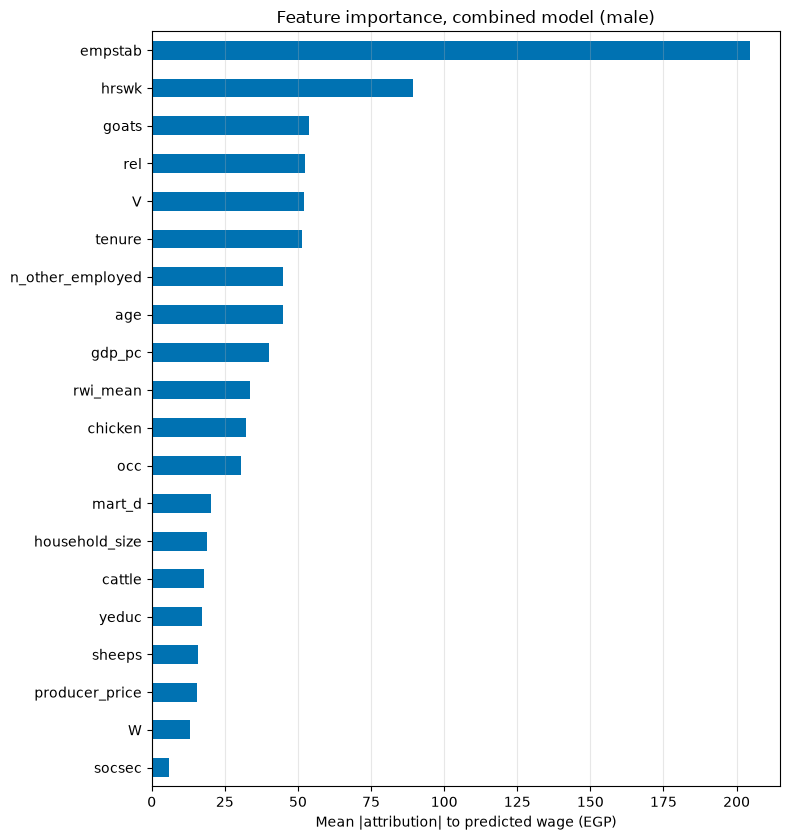

/Users/hemert/projects/egypt-survey-ml/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


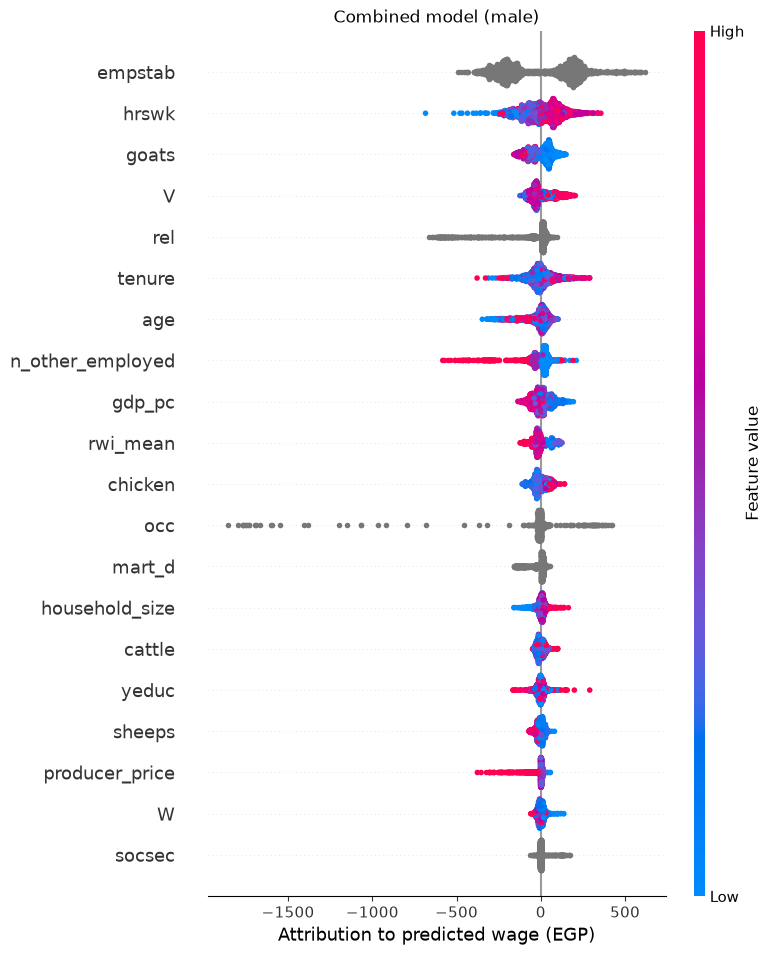

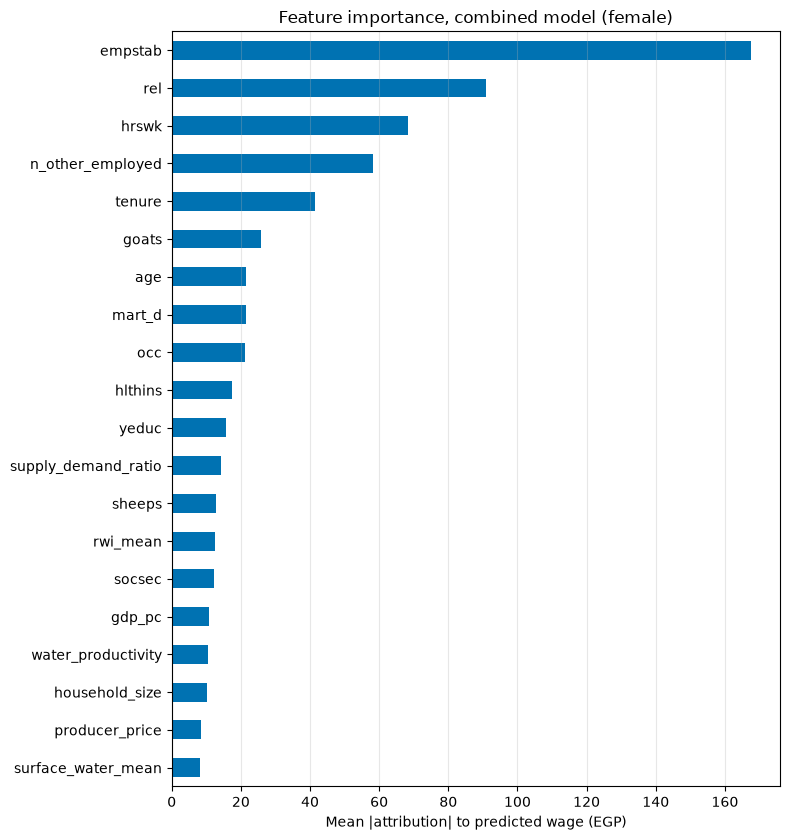

/Users/hemert/projects/egypt-survey-ml/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


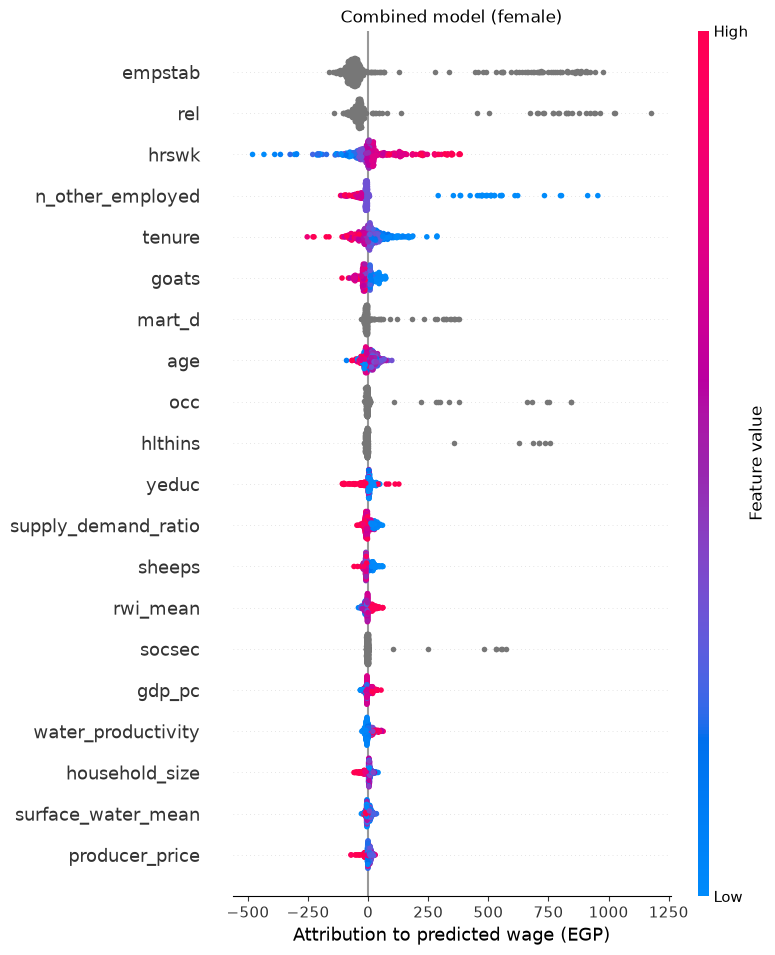

,male,female
empstab,204.617209,167.554581
hrswk,89.503468,68.386791
goats,53.777881,25.731112
rel,52.506853,90.919826
V,52.030986,6.557554
tenure,51.289156,41.354123
n_other_employed,44.976530,58.157022
age,44.853907,21.571697
gdp_pc,40.253726,10.746487
rwi_mean,33.706216,12.530596


In [12]:
# Feature importance of the combined model (classifier x regressor, all draws): SHAP values of both models are
# converted to EGP, combined so they add up to P(paid) * wage, and averaged over the ensemble members.
# Takes roughly 12 minutes for both sexes (SHAP for every member).
from egypt_survey_ml.explain import combined_shap, plot_importance, plot_beeswarm

FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

shap_male = combined_shap(ds, male_members, 'male')
shap_female = combined_shap(ds, female_members, 'female')

importance = pd.DataFrame({
    'male': shap_male.importance(weighted=True),
    'female': shap_female.importance(weighted=True),
}).sort_values('male', ascending=False)

for sex, res in [('male', shap_male), ('female', shap_female)]:
    plot_importance(res.importance(weighted=True), top=20, title=f'Feature importance, combined model ({sex})')
    # plt.savefig(FIGURE_DIR / f'shap-importance-combined-{sex}.png')
    plt.show()

    # beeswarm: x = effect on the predicted wage (EGP), colour = feature value (grey = categorical)
    plot_beeswarm(res, top=20, title=f'Combined model ({sex})', show=False)
    # plt.savefig(FIGURE_DIR / f'shap-beeswarm-combined-{sex}.png', bbox_inches='tight')
    plt.show()

importance

In [19]:
wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/wages_predictions_upper.csv")
nonzero_wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/nonzero_wages_predictions_upper.csv")

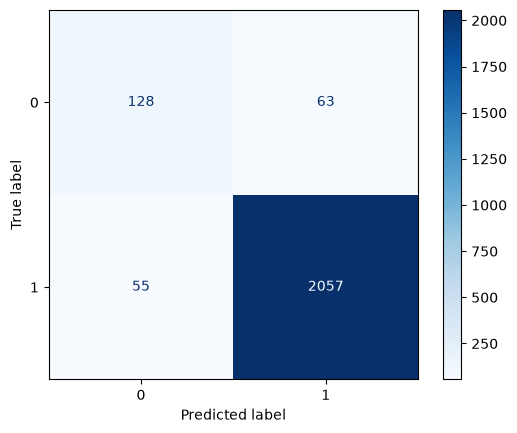

In [16]:
prediction_paid_male = pred_male.predicted_paid(threshold=0.70)
prediction_final_male = pred_male.final_wage()
true_paid_male = pred_male.true_paid
true_income_male = pred_male.true_income

y_pred = prediction_paid_male.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

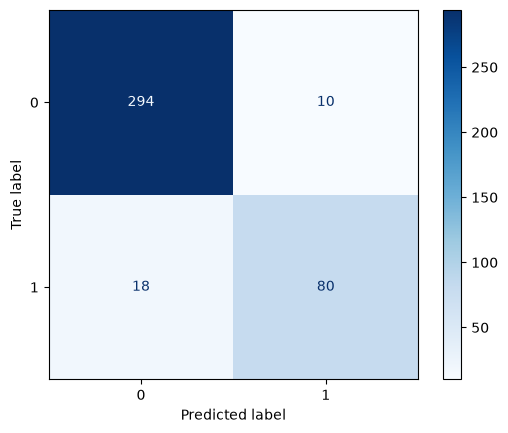

In [17]:
prediction_paid_female = pred_female.predicted_paid(threshold=0.33)
prediction_final_female = pred_female.final_wage()
true_paid_female = pred_female.true_paid
true_income_female = pred_female.true_income

y_pred = prediction_paid_female.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

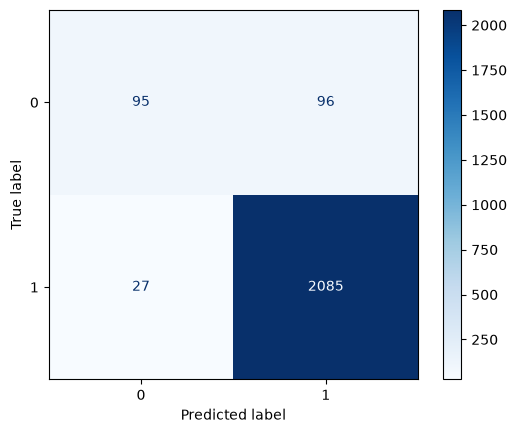

In [18]:
prediction_paid_male_nr = pred_male_nr.predicted_paid()
prediction_final_male_nr = pred_male_nr.final_wage()

y_pred = prediction_paid_male_nr.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

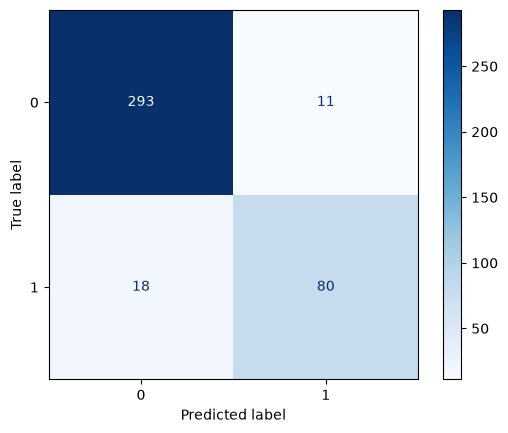

In [19]:
prediction_paid_female_nr = pred_female_nr.predicted_paid(threshold=0.33)
prediction_final_female_nr = pred_female_nr.final_wage()

y_pred = prediction_paid_female_nr.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

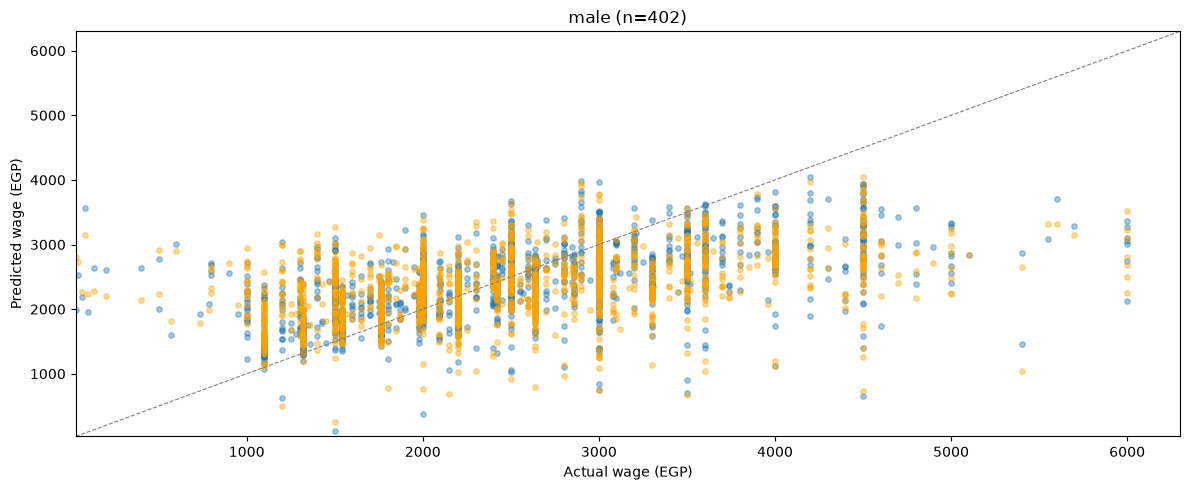

{'n': 2112, 'mae': 492.51337303529283, 'r2': 0.3409663646224297, 'spearman': np.float64(0.6289127174956083)}


In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

ax.scatter(y_true_male, y_pred_male, alpha=0.4, s=15)
ax.scatter(y_true_male, y_pred_nr_male, alpha=0.4, s=15, color='orange')
lims = [0.95 * min(y_true_male.min(), y_pred_male.min()), max(y_true_male.max(), y_pred_male.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"male (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_male),
    "mae": mean_absolute_error(y_true_male, y_pred_male),
    "r2": r2_score(y_true_male, y_pred_male),
    "spearman": sstats.spearmanr(y_true_male, y_pred_male).correlation,
}
print(metrics)

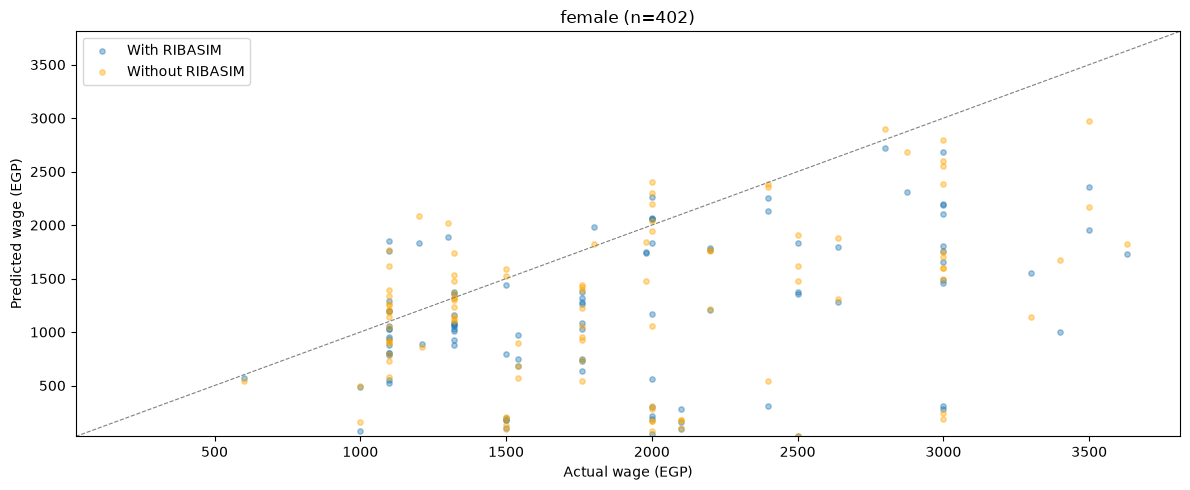

{'n': 98, 'mae': 795.660524689038, 'r2': -1.0856729934662672, 'spearman': np.float64(0.3796786213813294)}
{'n': 98, 'mae': 747.76866085625, 'r2': -0.9873848392178302, 'spearman': np.float64(0.3584657714033742)}


In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

ax.scatter(y_true_female, y_pred_female, alpha=0.4, s=15, label='With RIBASIM')
ax.scatter(y_true_female, y_pred_nr_female, alpha=0.4, s=15, color='orange', label='Without RIBASIM')
lims = [0.95 * min(y_true_female.min(), y_pred_female.min()), max(y_true_female.max(), y_pred_female.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"female (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
ax.legend()
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_female),
    "r2": r2_score(y_true_female, y_pred_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_female).correlation,
}
metrics_nr = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_nr_female),
    "r2": r2_score(y_true_female, y_pred_nr_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_nr_female).correlation,
}
print(metrics)
print(metrics_nr)

In [23]:
FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

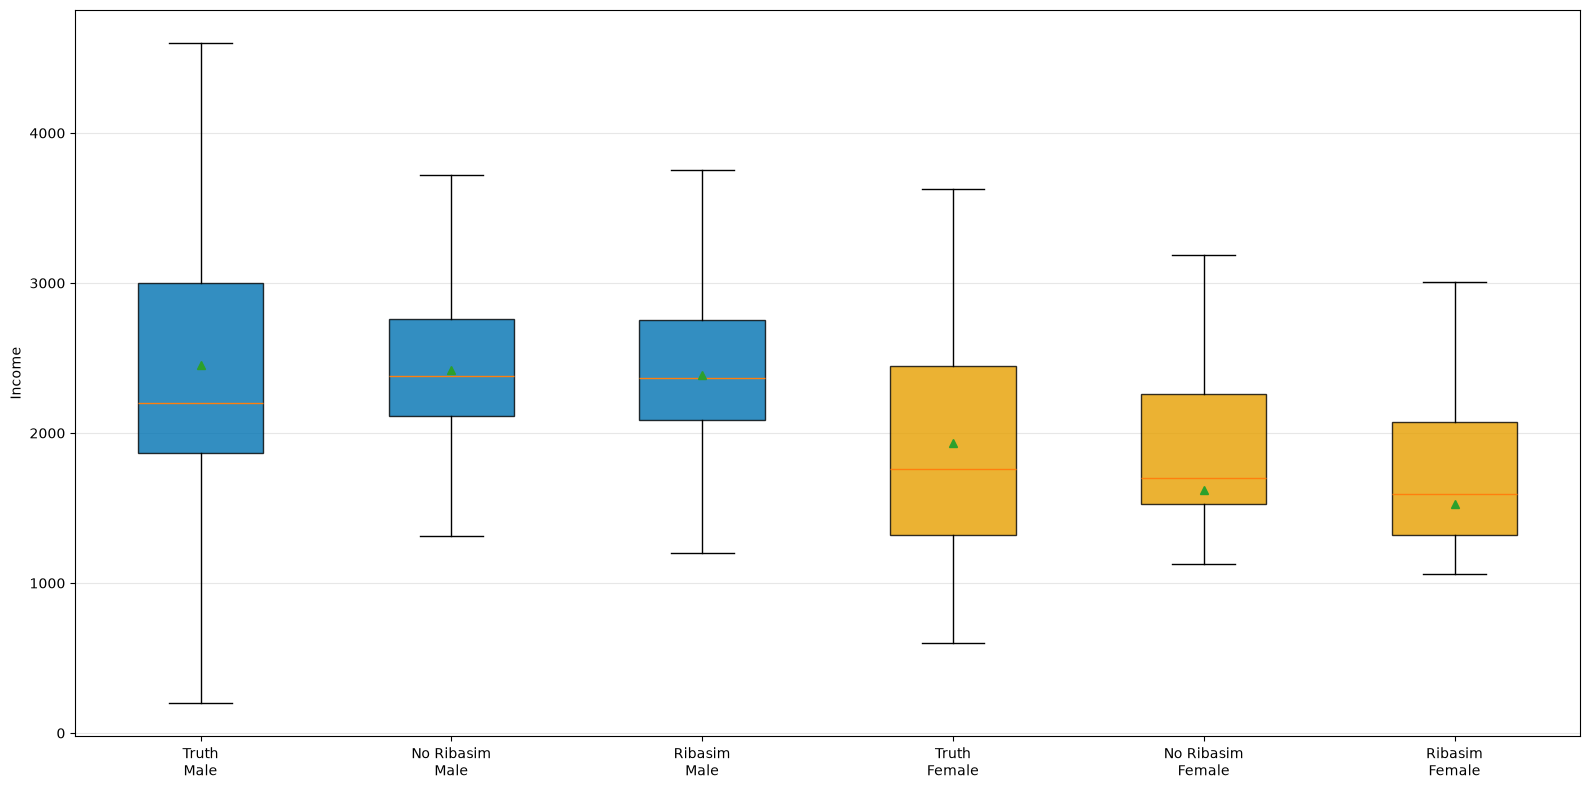

<Figure size 640x480 with 0 Axes>

In [65]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

labels = [
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
]

bp = ax.boxplot(
    data,
    patch_artist=True,
    showmeans=True,
    showfliers=False,
)

colors = [
    "#0072B2", "#0072B2",
    "#0072B2", "#E69F00",
    "#E69F00", "#E69F00",
]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.8)

ax.set_xticklabels(labels)

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(FIGURE_DIR / 'baseline-box-plots-with-hrs-22.png')

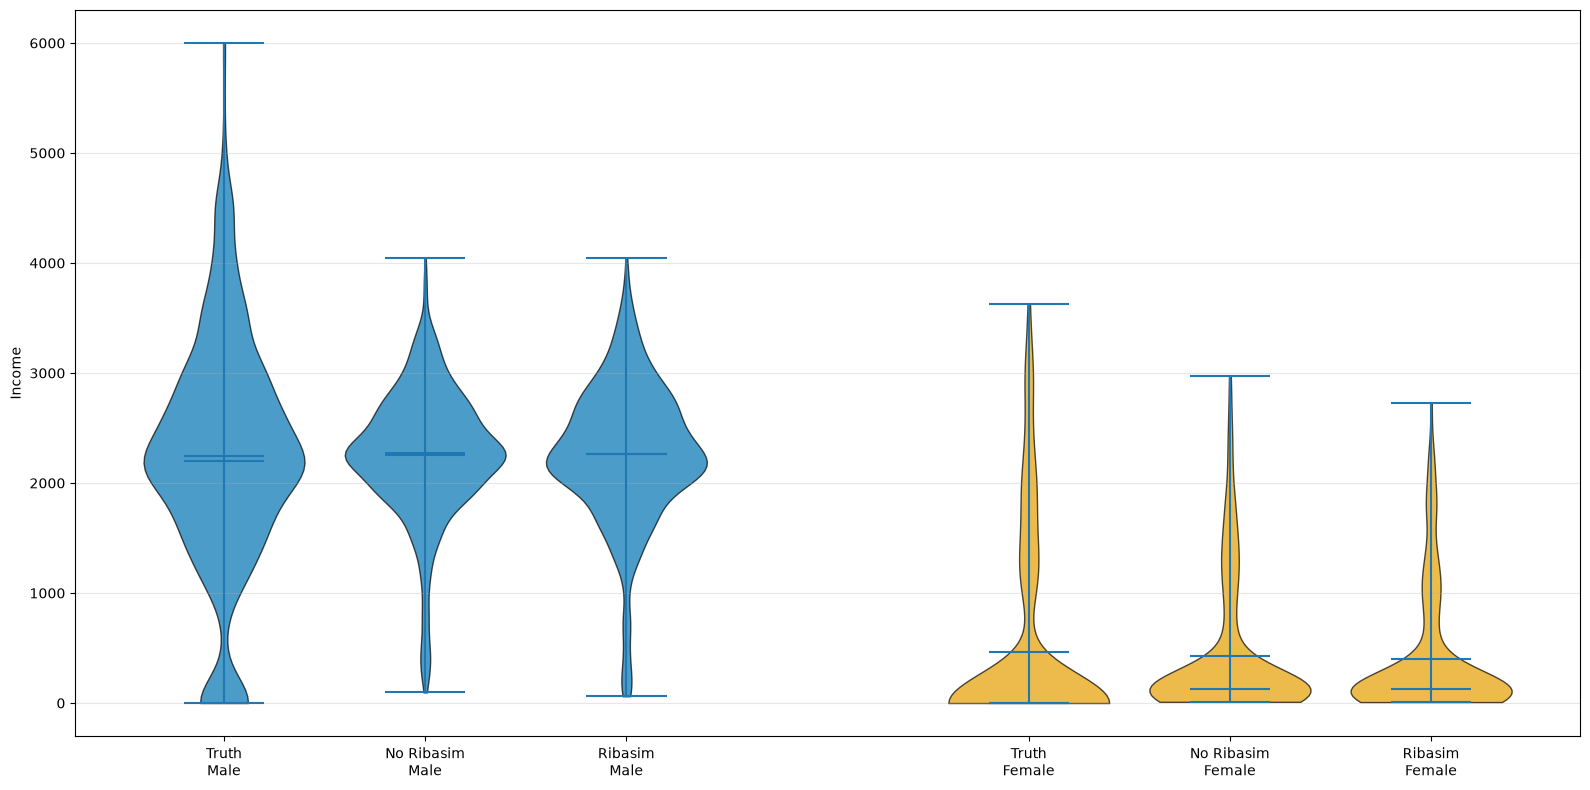

In [24]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

positions = [1, 2, 3, 5, 6, 7]

vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.8,
    showmeans=True,
    showmedians=True,
)

colors = [
    "#0072B2", "#0072B2",  # Truth
    "#0072B2", "#E69F00",  # Ribasim
    "#E69F00", "#E69F00",  # No Ribasim
]

for body, color in zip(vp["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.7)

ax.set_xticks(positions)
ax.set_xticklabels([
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
])

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
# plt.show()
plt.savefig(FIGURE_DIR / 'baseline-violin-plots-with-hrs-22.png')